# CECS 427 — Assignment 3  
## Positive & Negative Relationships

**Submission:** upload this notebook (`.ipynb`) with code + short written answers.

### Conventions (signed graphs)
- Each edge has a sign stored as an edge attribute: `sign = +1` (positive) or `sign = -1` (negative).
- Unless stated otherwise, graphs are **undirected**.


In [1]:
# Imports / setup
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from itertools import combinations
from collections import deque


## Below are the variables used in assignment :

- `n`: number of nodes (size of the graph).
- `p_pos`: probability an edge is **positive** (`sign = +1`) when generating random signed graphs.
- `sign`: edge attribute; `+1` = positive edge, `-1` = negative edge.
- `a, b, c`: three distinct nodes used to represent a triangle.
- `trials`: number of random graphs simulated for an estimate (larger → smoother results).
- `p_values`: list/array of probabilities to test (e.g., 0.0, 0.1, …, 1.0).
- `color`: dictionary mapping a node → 0/1 label during bipartite checking (two “sides”).
- `X, Y`: sets of nodes representing the 2-group partition when a graph is balanced.
- `groups`: list of sets (used for weak balance partitions into k groups).
- `witness` / `certificate`: a small counterexample explaining why a condition fails.

## Part A — Triangle Balance in Signed Complete Graphs

A signed **complete graph** is balanced when **every triangle** is balanced.

In this assignment, treat a triangle as balanced if it has an **odd** number of positive edges:
- `+++`  (3 positive edges), or
- `+--`  (exactly 1 positive edge)

### Tasks

**A1 — Build & visualize one signed complete graph**
1. Values for `n` and `p_pos` are provided.
2. A signed complete graph `K_n` with an edge attribute `sign ∈ {+1, -1}` is generated.
3. Draw the graph so that **positive** and **negative** edges are clearly distinguishable (e.g., different colors; solid vs dashed).

**A2 — Triangle balance**
1. Implement `is_triangle_balanced(G, a, b, c)`.
2. Compute the **fraction of balanced triangles** in your graph.
3. Print: total triangles, balanced triangles, and the fraction.

**A3 — Simulation + plot (detailed)**
1. Choose a fixed `n` (e.g., 12) and a list of probabilities `p_values` (e.g., 0.0, 0.1, …, 1.0).
2. For each `p_pos` in `p_values`, generate **many** random signed complete graphs (`trials`, e.g., 30).
3. For each graph:
   - enumerate all triangles `(a,b,c)`,
   - compute the fraction that are balanced.
4. For each `p_pos`, compute the **mean** fraction (and optionally the **std** across trials).
5. Plot: x-axis = `p_pos`, y-axis = mean fraction of balanced triangles (label everything clearly).
6. Write a short interpretation (4–6 sentences) in the interpretation box below.


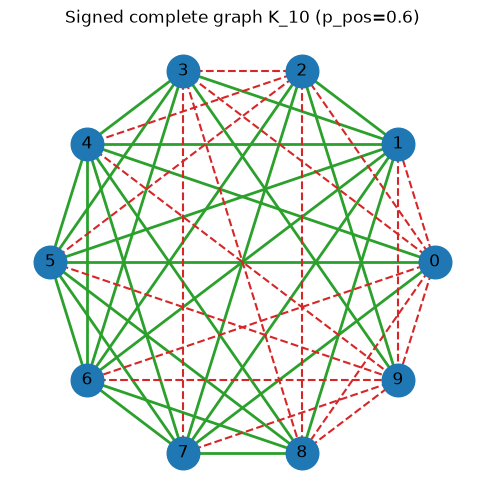

In [2]:
# A1 — Random signed complete graph + visualization

def make_signed_complete_graph(n, p_pos=0.5, seed=None):
    """Return K_n with each edge labeled sign=+1 with prob p_pos, else sign=-1."""
    rng = np.random.default_rng(seed)
    G = nx.complete_graph(n)
    for u, v in G.edges():
        G.edges[u, v]["sign"] = 1 if rng.random() < p_pos else -1
    return G

n = 10
p_pos = 0.6
G = make_signed_complete_graph(n, p_pos=p_pos, seed=7)

pos = nx.circular_layout(G)
pos_edges = [(u, v) for u, v in G.edges() if G.edges[u, v]["sign"] == 1]
neg_edges = [(u, v) for u, v in G.edges() if G.edges[u, v]["sign"] == -1]

plt.figure(figsize=(6, 6))
nx.draw_networkx_nodes(G, pos, node_size=550)
nx.draw_networkx_labels(G, pos)

# Requirements:
#   - Positive edges must be SOLID and one color.
#   - Negative edges must be DASHED and a different color.

# Positive edges
nx.draw_networkx_edges(
    G, pos,
    edgelist=pos_edges,
    edge_color="tab:green",
    style="solid",
    width=2,
)

#Negative edges
nx.draw_networkx_edges(
    G, pos,
    edgelist=neg_edges,
    edge_color="tab:red",
    style="dashed",
    width=1.5,
)

plt.title(f"Signed complete graph K_{n} (p_pos={p_pos})")
plt.axis("off")
plt.show()


In [3]:
# A2 — Triangle balance + fraction of balanced triangles

def triangle_signs(G, a, b, c):
    """Return the 3 edge signs for triangle (a,b,c) as a list."""
    return [G.edges[a, b]["sign"], G.edges[a, c]["sign"], G.edges[b, c]["sign"]]

def is_triangle_balanced(G, a, b, c):
    """Return True iff triangle (a,b,c) has an odd number of + edges."""
    signs = triangle_signs(G, a, b, c)       # e.g. [1, -1, -1]
    num_positive = signs.count(1)            # how many edges are +1

    if num_positive == 3 or num_positive == 1:
        return True
    return False   

total_triangles = 0
balanced_triangles = 0

for a, b, c in combinations(G.nodes(), 3):
    total_triangles += 1
    if is_triangle_balanced(G, a, b, c):
        balanced_triangles += 1

p_balanced = balanced_triangles / total_triangles

print("Total triangles:", total_triangles)
print("Balanced triangles:", balanced_triangles)
print("Fraction balanced:", p_balanced)


Total triangles: 120
Balanced triangles: 74
Fraction balanced: 0.6166666666666667


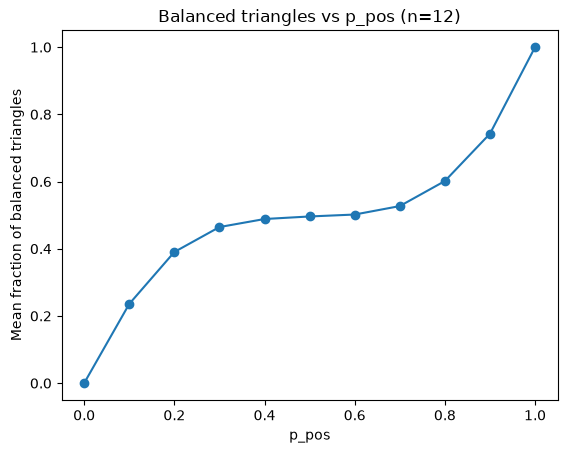

In [4]:
# A3 — Simulation plot: fraction balanced vs p_pos

def fraction_balanced_triangles(n, p_pos, trials=20, seed=0):
    """Estimate how often triangles are balanced in random signed complete graphs.

    Parameters
    ----------
    n : int
        Number of nodes in K_n.
    p_pos : float
        Probability an edge is positive (+1).
    trials : int
        How many random graphs to sample.
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    mean_frac : float
        Mean fraction of balanced triangles across trials.
    std_frac : float
        Standard deviation across trials which helps show variability.
    """
    rng = np.random.default_rng(seed)
    fractions = []
    
    for i in range(trials):

        G = make_signed_complete_graph(n, p_pos, seed=int(rng.integers(0, 10**9)))
        
        total = 0
        balanced = 0
        for a, b, c in combinations(G.nodes(), 3):
            total += 1
            if is_triangle_balanced(G, a, b, c):
                balanced += 1
        
        fractions.append(balanced / total)
    
    return np.mean(fractions), np.std(fractions)

# Choose a fixed n for the experiment
n = 12

# p_values is the list of p_pos values we will test (0.0, 0.1, ..., 1.0)
p_values = np.linspace(0, 1, 11)

# - For each p in p_values, compute (mean, std) using fraction_balanced_triangles(...)
means = []
stds = []
for p in p_values:
    mean, std = fraction_balanced_triangles(n, p, trials=30)
    means.append(mean)
    stds.append(std)

plt.plot(p_values, means, marker="o")
plt.xlabel("p_pos")
plt.ylabel("Mean fraction of balanced triangles")
plt.title(f"Balanced triangles vs p_pos (n={n})")
plt.show()


**A3 Interpretation :**  
Describe how the fraction of balanced triangles changes as `p_pos` goes from 0 to 1, and why.


The balanced-triangle fraction starts at 0 when every edge is negative and reaches 1 when every edge is positive. A triangle is balanced when it has either one or three positive edges. For independent edge signs, its expected balanced probability is p_pos**3 + 3*p_pos*(1-p_pos)**2. This equals 0.5 at p_pos = 0.5 and increases overall as p_pos rises. The simulated curve can fluctuate slightly because each point averages only 30 random graphs.

---
## Part B — Balance Theorem vs. Weak Balance (Complete Graphs)

### Tasks

**B1 (Balance check):** Determine whether the graph is balanced under the **two-faction** theorem.  
If balanced, return the partition `(X, Y)`. If not, return a **small witness** showing what rule fails.

**B2 (Weak balance check):** Determine whether the graph is weakly balanced (may allow `k ≥ 1` groups).  
If weakly balanced, return a list of groups. If not, return a **witness triangle** that violates the rule.

**B3 (Experiment + plot — detailed):**
1. For each `p_pos` in a list (e.g., 0.0 to 1.0), generate many random signed complete graphs.
2. Estimate:
   - `pb[p]` = fraction of graphs that are **balanced**
   - `pw[p]` = fraction of graphs that are **weakly balanced**
3. Plot both curves on the same axes with a legend and clear labels.
4. Write a short interpretation (5–8 sentences) below explaining the difference.

In [5]:
# B1 — Balance checker (2 groups)

def is_balanced_complete(G):
    nodes = list(G.nodes())
    if not nodes:
        return True, (set(), set()), None

    anchor = nodes[0]
    X = {anchor}
    Y = set()
    for neighbor in nodes[1:]:
        if G.edges[anchor, neighbor]["sign"] == 1:
            X.add(neighbor)
        else:
            Y.add(neighbor)

    # Edges must be positive within groups and negative between groups.
    # A wrong sign gives an unbalanced triangle with the anchor.
    for u, v, data in G.edges(data=True):
        same_faction = (u in X) == (v in X)
        expected_sign = 1 if same_faction else -1
        if data["sign"] != expected_sign:
            triangle = (anchor, u, v)
            signs = tuple(G.edges[a, b]["sign"] for a, b in
                          ((anchor, u), (anchor, v), (u, v)))
            return False, None, {
                "triangle": triangle,
                "signs": signs,
                "violating_edge": (u, v),
            }

    return True, (X, Y), None

balanced_example = nx.complete_graph(4)
balanced_factions = [{0, 1}, {2, 3}]
for u, v in balanced_example.edges():
    balanced_example.edges[u, v]["sign"] = (
        1 if any(u in faction and v in faction for faction in balanced_factions)
        else -1
    )

unbalanced_example = nx.complete_graph(3)
for edge, sign in { (0, 1): 1, (1, 2): 1, (0, 2): -1 }.items():
    unbalanced_example.edges[edge]["sign"] = sign

balanced_result = is_balanced_complete(balanced_example)
unbalanced_result = is_balanced_complete(unbalanced_example)
assert balanced_result[0] and balanced_result[1] is not None
assert not unbalanced_result[0] and unbalanced_result[2] is not None
witness = unbalanced_result[2]
assert set(witness["triangle"]) == {0, 1, 2}
assert sum(sign == 1 for sign in witness["signs"]) in (0, 2)
print("Balanced example:", balanced_result)
print("Unbalanced example:", unbalanced_result)


Balanced example: (True, ({0, 1}, {2, 3}), None)
Unbalanced example: (False, None, {'triangle': (0, 1, 2), 'signs': (1, -1, 1), 'violating_edge': (1, 2)})


In [6]:
# B2 — Weak balance checker (k groups)

def is_weakly_balanced_complete(G):
    # Nodes connected by positive edges belong to the same group.
    positive_graph = nx.Graph()
    positive_graph.add_nodes_from(G.nodes())
    positive_graph.add_edges_from(
        (u, v) for u, v, data in G.edges(data=True) if data["sign"] == 1
    )
    groups = [set(component) for component in nx.connected_components(positive_graph)]

    # A negative edge within a group breaks weak balance.
    # Use a shortest positive path to find a ++- witness triangle.
    for group in groups:
        for u, v in combinations(group, 2):
            if G.edges[u, v]["sign"] == -1:
                path = nx.shortest_path(positive_graph, source=u, target=v)
                for left, middle, right in zip(path, path[1:], path[2:]):
                    if G.edges[left, right]["sign"] == -1:
                        witness = (left, middle, right)
                        signs = tuple(G.edges[a, b]["sign"] for a, b in
                                      ((left, middle), (middle, right), (left, right)))
                        assert signs == (1, 1, -1)
                        return False, None, witness

    return True, groups, None

# Three all-negative nodes are weakly balanced, but not balanced.
weak_only_example = nx.complete_graph(3)
for u, v in weak_only_example.edges():
    weak_only_example.edges[u, v]["sign"] = -1

# A ++- triangle breaks weak balance.
not_weak_example = nx.complete_graph(3)
for edge, sign in { (0, 1): 1, (1, 2): 1, (0, 2): -1 }.items():
    not_weak_example.edges[edge]["sign"] = sign

weak_result = is_weakly_balanced_complete(weak_only_example)
not_weak_result = is_weakly_balanced_complete(not_weak_example)
assert weak_result[0] and len(weak_result[1]) == 3
assert not is_balanced_complete(weak_only_example)[0]
assert not not_weak_result[0]
assert set(not_weak_result[2]) == {0, 1, 2}
print("Weakly balanced, not balanced example:", weak_result)
print("Not weakly balanced example:", not_weak_result)


Weakly balanced, not balanced example: (True, [{0}, {1}, {2}], None)
Not weakly balanced example: (False, None, (0, 1, 2))


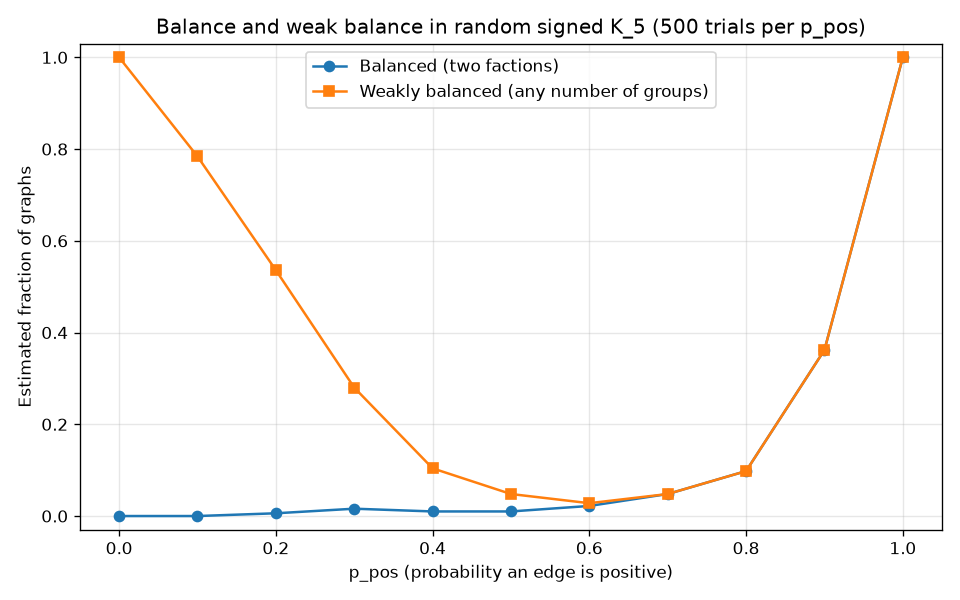

In [7]:
# B3 — Empirical comparison: balanced vs weakly balanced

def estimate_probabilities(n=10, trials=200, seed=0):
    """Estimate balance probabilities on a fixed grid of positive-edge rates."""
    rng = np.random.default_rng(seed)
    p_values = np.linspace(0, 1, 11)
    pb, pw = [], []
    for p in p_values:
        bal_count = 0
        weak_count = 0
        for _ in range(trials):
            Gt = make_signed_complete_graph(n, p_pos=p, seed=int(rng.integers(0, 10**9)))
            is_bal, _, _ = is_balanced_complete(Gt)
            is_w, _, _ = is_weakly_balanced_complete(Gt)
            bal_count += int(is_bal)
            weak_count += int(is_w)
        pb.append(bal_count / trials)
        pw.append(weak_count / trials)
    return p_values, pb, pw

# Use five nodes to make both curves visible; the seed keeps results repeatable.
n = 5
trials = 500
p_values, pb, pw = estimate_probabilities(n=n, trials=trials, seed=0)

plt.figure(figsize=(8, 5))
plt.plot(p_values, pb, marker="o", label="Balanced (two factions)")
plt.plot(p_values, pw, marker="s", label="Weakly balanced (any number of groups)")
plt.xlabel("p_pos (probability an edge is positive)")
plt.ylabel("Estimated fraction of graphs")
plt.title(f"Balance and weak balance in random signed K_{n} ({trials} trials per p_pos)")
plt.ylim(-0.03, 1.03)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**B3 Interpretation :**  
Explain why weak balance is typically easier to satisfy than balance, and how the allowed structure differs.

Balance allows up to two groups, while weak balance allows more. Both require positive edges within groups and negative edges between groups. This makes weak balance easier to satisfy, so its curve stays at or above the balance curve. When `p_pos = 0`, all edges are negative, so our five-node graph is weakly balanced with each node in its own group, but not balanced. When `p_pos = 1`, all edges are positive, so both rules are satisfied by one group.


---
## Part C — Structural Balance for General (Non-Complete) Signed Graphs

For general signed graphs, we will use the reduction idea from lecture:

1) Build the **positive-edge subgraph** and take its connected components (**supernodes**).  
2) Check whether any negative edge occurs inside a positive supernode. If so, the graph is immediately not balanced.  
3) Build a **reduced graph** whose nodes are supernodes; add an edge between two supernodes if there is a **negative** edge between them in the original graph.  
4) If there is no internal negative edge, the original signed graph is balanced iff the reduced graph is **bipartite**.

### Tasks

**C1.** Build and draw the three provided signed graphs (make + vs − edges visually distinct).

**C2.** Implement `supernode_reduction(G)` and print:
- the supernodes (positive components),
- any negative edges that occur *inside* a supernode,
- the reduced graph edges.

Also draw the reduced graph.

**C3.** Implement `bfs_bipartite(reduced_G, start)` **from scratch** and use it to decide whether each graph is balanced:

1. If a negative edge occurs inside a positive supernode, report the graph as not balanced.
2. Otherwise, test whether the reduced graph is bipartite using BFS.
3. If the reduced graph is bipartite, return the induced 2-way partition `(X, Y)` of original nodes.
4. If not bipartite, return a small certificate such as an edge connecting two same-colored supernodes.

The three graphs are designed to illustrate different cases:
- **G1:** balanced, with a non-trivial even cycle in the reduced graph,
- **G2:** not balanced because the reduced graph contains an odd cycle,
- **G3:** not balanced because a negative edge occurs inside a positive supernode.

G1: 12 nodes, 12 edges (6 positive, 6 negative)


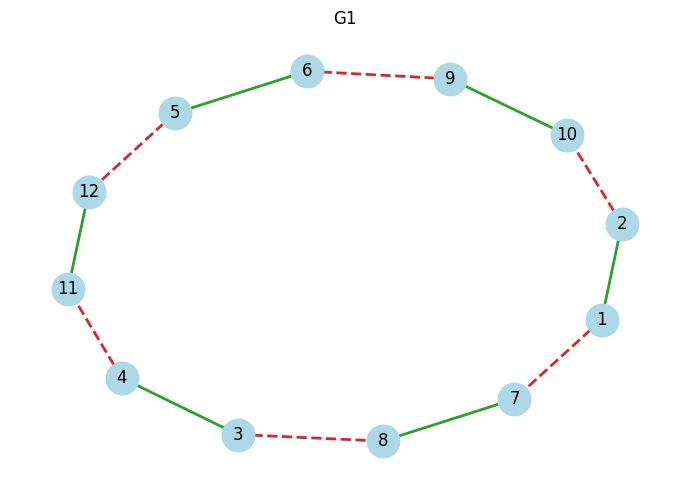

G2: 12 nodes, 12 edges (6 positive, 6 negative)


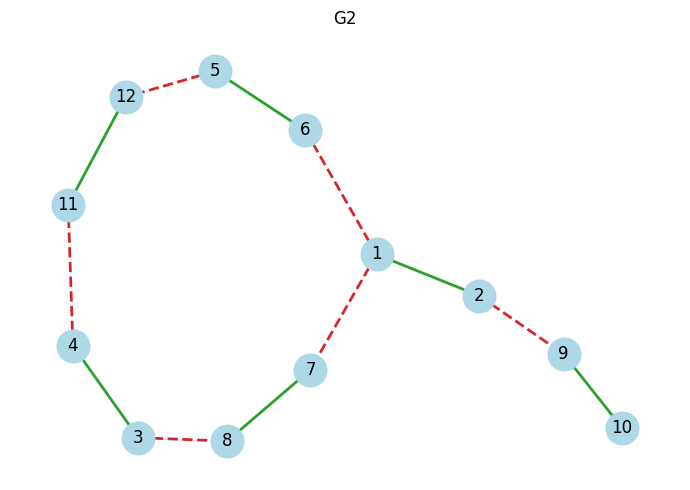

G3: 7 nodes, 7 edges (4 positive, 3 negative)


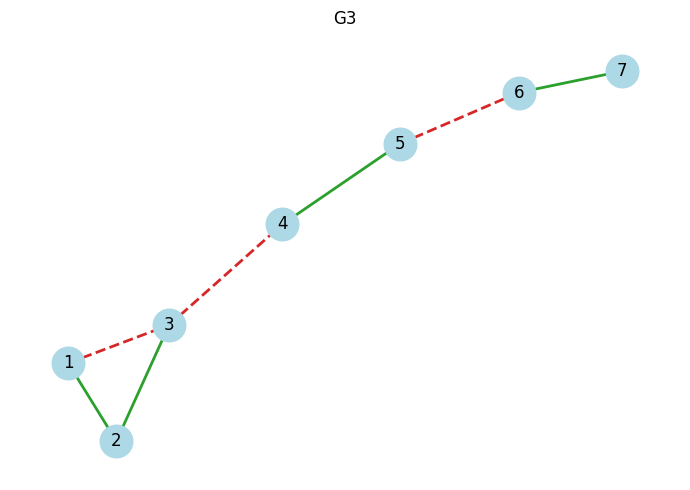

In [8]:
# C1 — Build + draw three signed graphs

def make_signed_graph(edge_list):
    """Build an undirected graph with sign = +1 or -1 on each edge."""
    G = nx.Graph()
    for u, v, sign in edge_list:
        G.add_edge(u, v, sign=sign)
    return G


def draw_signed_graph(G, title=""):
    """Draw positive edges solid green and negative edges dashed red."""
    pos = nx.spring_layout(G, seed=42)
    positive = [(u, v) for u, v, data in G.edges(data=True)
                if data["sign"] == 1]
    negative = [(u, v) for u, v, data in G.edges(data=True)
                if data["sign"] == -1]

    plt.figure(figsize=(7, 5))
    nx.draw_networkx_nodes(G, pos, node_size=550, node_color="lightblue")
    nx.draw_networkx_labels(G, pos)
    nx.draw_networkx_edges(G, pos, edgelist=positive,
                           edge_color="tab:green", style="solid", width=2)
    nx.draw_networkx_edges(G, pos, edgelist=negative,
                           edge_color="tab:red", style="dashed", width=2)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# G1:
edges1 = [
    (1, 2,   1),
    (3, 4,   1),
    (5, 6,   1),
    (7, 8,   1),
    (9, 10,  1),
    (11, 12, 1),
    (1, 7,   -1),
    (8, 3,   -1),
    (4, 11,  -1),
    (12, 5,  -1),
    (6, 9,   -1),
    (10, 2,  -1),
]


# G2:
edges2 = [
    (1, 2,   1),
    (3, 4,   1),
    (5, 6,   1),
    (7, 8,   1),
    (9, 10,  1),
    (11, 12, 1),
    (1, 7,   -1),
    (8, 3,   -1),
    (4, 11,  -1),
    (12, 5,  -1),
    (6, 1,   -1),
    (2, 9,   -1),
]


# G3:
edges3 = [
    (1, 2,  1),
    (2, 3,  1),
    (1, 3, -1),
    (4, 5,  1),
    (6, 7,  1),
    (3, 4, -1),
    (5, 6, -1),
]



G1 = make_signed_graph(edges1)
G2 = make_signed_graph(edges2)
G3 = make_signed_graph(edges3)

for name, graph in (("G1", G1), ("G2", G2), ("G3", G3)):
    positive_count = sum(data["sign"] == 1
                         for _, _, data in graph.edges(data=True))
    negative_count = graph.number_of_edges() - positive_count
    print(f"{name}: {graph.number_of_nodes()} nodes, "
          f"{graph.number_of_edges()} edges "
          f"({positive_count} positive, {negative_count} negative)")
    draw_signed_graph(graph, name)


G1 supernodes:
  S0: [1, 2]
  S1: [3, 4]
  S2: [5, 6]
  S3: [7, 8]
  S4: [9, 10]
  S5: [11, 12]
Internal negative edges: []
Reduced graph edges: [(0, 3), (0, 4), (1, 3), (1, 5), (2, 4), (2, 5)]


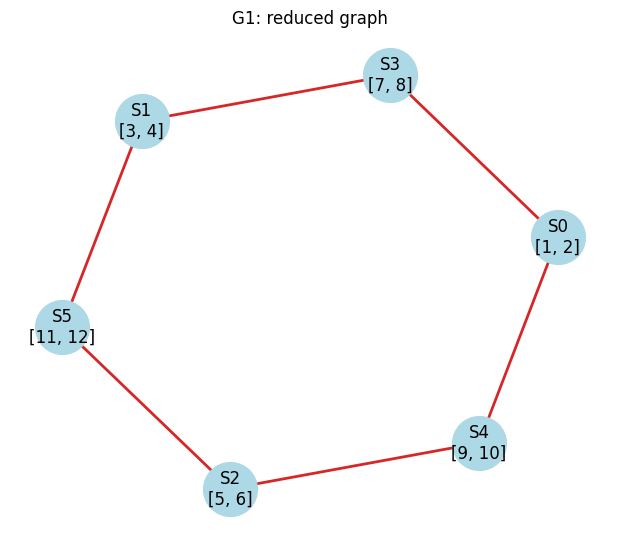


G2 supernodes:
  S0: [1, 2]
  S1: [3, 4]
  S2: [5, 6]
  S3: [7, 8]
  S4: [9, 10]
  S5: [11, 12]
Internal negative edges: []
Reduced graph edges: [(0, 2), (0, 3), (0, 4), (1, 3), (1, 5), (2, 5)]


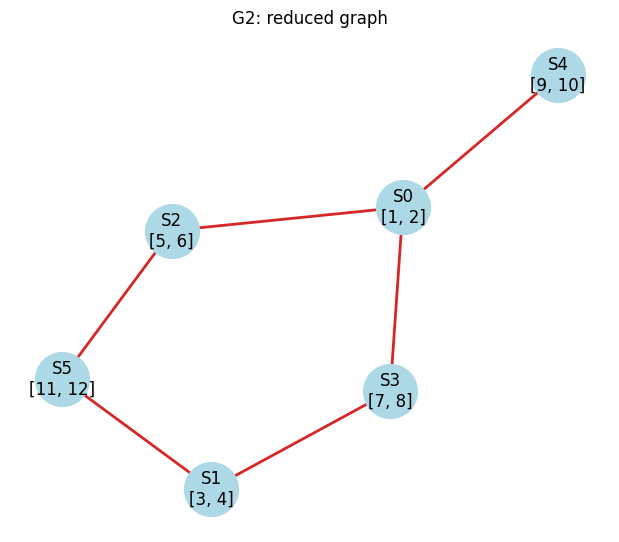


G3 supernodes:
  S0: [1, 2, 3]
  S1: [4, 5]
  S2: [6, 7]
Internal negative edges: [(1, 3)]
Reduced graph edges: [(0, 1), (1, 2)]


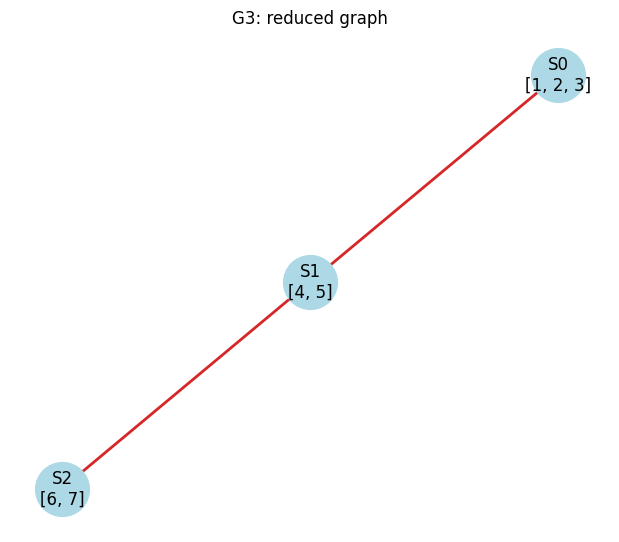

In [9]:
# C2 — Supernode reduction + reduced graph

def supernode_reduction(G):
    """Collapse positive components and retain negative edges between them."""
    positive_graph = nx.Graph()
    positive_graph.add_nodes_from(G.nodes())
    positive_graph.add_edges_from(
        (u, v) for u, v, data in G.edges(data=True) if data["sign"] == 1
    )
    supernodes = [set(component)
                  for component in nx.connected_components(positive_graph)]
    node_to_super = {
        node: index
        for index, component in enumerate(supernodes)
        for node in component
    }

    reduced_G = nx.Graph()
    reduced_G.add_nodes_from(range(len(supernodes)))
    internal_negative_edges = []
    for u, v, data in G.edges(data=True):
        if data["sign"] == -1:
            su, sv = node_to_super[u], node_to_super[v]
            if su == sv:
                internal_negative_edges.append((u, v))
            else:
                reduced_G.add_edge(su, sv, original_edge=(u, v))

    return supernodes, node_to_super, reduced_G, internal_negative_edges


for name, graph in (("G1", G1), ("G2", G2), ("G3", G3)):
    supernodes, node_to_super, reduced_G, internal_negative_edges = (
        supernode_reduction(graph)
    )
    print(f"\n{name} supernodes:")
    for index, component in enumerate(supernodes):
        print(f"  S{index}: {sorted(component)}")
    print("Internal negative edges:", internal_negative_edges)
    print("Reduced graph edges:", sorted(reduced_G.edges()))

    labels = {index: f"S{index}\n{sorted(component)}"
              for index, component in enumerate(supernodes)}
    plt.figure(figsize=(6, 5))
    nx.draw(reduced_G, nx.spring_layout(reduced_G, seed=42),
            labels=labels, with_labels=True, node_color="lightblue",
            node_size=1500, edge_color="tab:red", width=2)
    plt.title(f"{name}: reduced graph")
    plt.show()

In [10]:
# C3 — BFS bipartite test from scratch + balance decision

def bfs_bipartite(reduced_G, start):
    """Color one connected component using BFS."""
    color = {start: 0}
    queue = deque([start])
    while queue:
        u = queue.popleft()
        for v in reduced_G.neighbors(u):
            if v not in color:
                color[v] = 1 - color[u]
                queue.append(v)
            elif color[v] == color[u]:
                return False, color, (u, v)
    return True, color, None


def is_balanced_general_signed_graph(G):
    """Return a two-way partition or a certificate of imbalance."""
    supernodes, node_to_super, reduced_G, internal_negative_edges = (
        supernode_reduction(G)
    )
    if internal_negative_edges:
        return False, None, {
            "reason": "negative edge inside a positive supernode",
            "edge": internal_negative_edges[0],
            "supernode": node_to_super[internal_negative_edges[0][0]],
        }

    colors = {}
    for start in reduced_G:
        if start in colors:
            continue
        is_bipartite, component_colors, conflict = (
            bfs_bipartite(reduced_G, start)
        )
        if not is_bipartite:
            u, v = conflict
            return False, None, {
                "reason": "reduced graph is not bipartite",
                "conflict_supernodes": conflict,
                "original_negative_edge": reduced_G.edges[u, v]["original_edge"],
            }
        colors.update(component_colors)

    X = set().union(*(supernodes[i] for i in colors if colors[i] == 0))
    Y = set().union(*(supernodes[i] for i in colors if colors[i] == 1))
    return True, (X, Y), None


for name, graph in (("G1", G1), ("G2", G2), ("G3", G3)):
    balanced, partition, certificate = is_balanced_general_signed_graph(graph)
    print(f"{name} balanced: {balanced}")
    if balanced:
        X, Y = partition
        print("  X:", sorted(X), "Y:", sorted(Y))
    else:
        print("  Certificate:", certificate)

G1 balanced: True
  X: [1, 2, 3, 4, 5, 6] Y: [7, 8, 9, 10, 11, 12]
G2 balanced: False
  Certificate: {'reason': 'reduced graph is not bipartite', 'conflict_supernodes': (1, 5), 'original_negative_edge': (4, 11)}
G3 balanced: False
  Certificate: {'reason': 'negative edge inside a positive supernode', 'edge': (1, 3), 'supernode': 0}


### Conceptual Questions

1. In a complete graph, choose any node A. Put A and all its positive neighbors in X, and its negative neighbors in Y. Every triangle containing A is balanced only when edges within X or Y are positive and edges across the sets are negative. Because all pairs have edges, this forces a global two-faction structure; Y may be empty.
2. Weak balance permits any number of groups. Positive edges must lie within groups and negative edges between groups, but all-negative triangles are allowed. Thus three or more mutually hostile groups may be weakly balanced even though they are not balanced.
3. Along any cycle, a two-faction assignment changes sides at every negative edge and stays on the same side at every positive edge. After a closed walk it must return to the starting side. An odd number of negative edges would put the start on the opposite side, so the graph is imbalanced.

---
## Part D — Approximately Balanced Networks

### Tasks

**D1 (Approximate balance theorem):** Suppose 99.9% of all triangles in a complete signed graph are balanced.  
1. Compute `epsilon` where `1 - epsilon = 0.999`.
2. Compute `delta = epsilon**(1/3)`.
3. Compute `1 - delta`.
4. Briefly explain what `1 - delta` means in terms of the approximate global structure of the graph.

**D2 (Good node + approximate partition):**  
The **weight** of a node is the number of unbalanced triangles containing that node.
1. Compute the weight of every node.
2. Find a node with minimum weight and call it the **good node** `A`.
3. Use `A` to form two sets:
   - `X` = `A` and all positive neighbors of `A`
   - `Y` = all negative neighbors of `A`
4. Count the edges that violate the expected balanced structure:
   - negative edges inside `X`
   - negative edges inside `Y`
   - positive edges between `X` and `Y`
5. Report the fraction of wrong-sign edges.


In [11]:
# D1 — Approximate balance theorem

balanced_fraction = 0.999
epsilon = 1 - balanced_fraction
delta = epsilon ** (1 / 3)
approx_fraction = 1 - delta

print(f"epsilon: {epsilon:.3f}")
print(f"delta: {delta:.3f}")
print(f"Approximate global fraction: {approx_fraction:.3f}")

epsilon: 0.001
delta: 0.100
Approximate global fraction: 0.900


**D1 Interpretation:** Here epsilon = 0.001, delta is about 0.1, and 1 - delta is about 0.9. The approximate balance guarantee says there is a two-group partition whose expected sign pattern agrees with at least about 90% of all edges. The graph can still contain some unbalanced triangles and wrong-sign edges; 90% is a guaranteed lower bound, not an exact measurement for a particular graph.

In [12]:
# D2 — Good node + approximate partition

def node_unbalanced_weights(G):
    """Count unbalanced triangles containing each node."""
    weights = {node: 0 for node in G.nodes()}
    for a, b, c in combinations(G.nodes(), 3):
        if not is_triangle_balanced(G, a, b, c):
            weights[a] += 1
            weights[b] += 1
            weights[c] += 1
    return weights


def find_good_node(G):
    """Return a node of minimum weight and that weight."""
    weights = node_unbalanced_weights(G)
    if not weights:
        return None, 0
    A = min(weights, key=weights.get)
    return A, weights[A]


def good_node_partition(G, A):
    """Put A and its friends in X; put its enemies in Y."""
    X = {A}
    Y = set()
    for neighbor in G.neighbors(A):
        if G.edges[A, neighbor]["sign"] == 1:
            X.add(neighbor)
        else:
            Y.add(neighbor)
    return X, Y


def wrong_sign_fraction(G, X, Y):
    """Count edges inconsistent with positive within and negative across."""
    wrong_edges = 0
    for u, v, data in G.edges(data=True):
        same_group = (u in X and v in X) or (u in Y and v in Y)
        expected_sign = 1 if same_group else -1
        wrong_edges += data["sign"] != expected_sign
    total_edges = G.number_of_edges()
    fraction_wrong = wrong_edges / total_edges if total_edges else 0.0
    return wrong_edges, total_edges, fraction_wrong


# Start with a balanced K_12, then flip two edges to make a near-balanced example.
G_demo = nx.complete_graph(12)
faction_one = set(range(6))
for u, v in G_demo.edges():
    G_demo.edges[u, v]["sign"] = (
        1 if (u in faction_one) == (v in faction_one) else -1
    )
for u, v in ((0, 1), (7, 8)):
    G_demo.edges[u, v]["sign"] *= -1

weights = node_unbalanced_weights(G_demo)
A, weight = find_good_node(G_demo)
X, Y = good_node_partition(G_demo, A)
wrong_edges, total_edges, fraction_wrong = wrong_sign_fraction(G_demo, X, Y)

print("Unbalanced-triangle weights:", weights)
print("Good node:", A, "weight:", weight)
print("X:", sorted(X))
print("Y:", sorted(Y))
print("Wrong-sign edges:", wrong_edges, "of", total_edges)
print("Wrong-sign fraction:", fraction_wrong)

Unbalanced-triangle weights: {0: 11, 1: 11, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 11, 8: 11, 9: 2, 10: 2, 11: 2}
Good node: 2 weight: 2
X: [0, 1, 2, 3, 4, 5]
Y: [6, 7, 8, 9, 10, 11]
Wrong-sign edges: 2 of 66
Wrong-sign fraction: 0.030303030303030304


**D2 Interpretation:** A few flipped edges create unbalanced triangles, so this graph is not perfectly balanced. The good node appears in the fewest unbalanced triangles, making its positive and negative ties a useful guide to the two groups. For the example above, that partition leaves 2 of 66 edges with the wrong sign, a fraction of about 0.0303. Most edges still follow the positive-within, negative-between pattern.